# Figure 3

Pairwise co-occurrence and mutual exclusivity analysis results across the *E. coli* ALE compendium.

- **A** (`axA`): number of mutated genes against number of endpoints, one point per experiment with at least two endpoints, colored by the direction of its significant pairs. Drawn in the last cell.
- **B** (`axB`, `axBT`, `axBR`): Fisher's exact test q against DISCOVER q for every pair with a q-value under both methods, with count bars along both axes. Drawn by `draw_qq` and `draw_marginals`.
- **C** (`axC`): Fisher-significant pairs per experiment, stacked by direction, with a dot for the experiments that also have a DISCOVER-significant pair. Drawn by `draw_concentration`.

Inputs: `data/qc/ecoli/qc_mutations.tsv` and `data/analysis/ecoli/all_experiments/pairwise_all_methods_gene.csv`. The experiments whose mutation data are not public have no rows in `qc_mutations.tsv`. For them, the figure reads `gene_by_endpoint.tsv` in `data/qc/ecoli/nonpublic/`.

Output: `figures/Figure_3/Figure_3.svg` and `figures/Figure_3/Figure_3.png`.

Environment A. The final layout is set in Adobe Illustrator.


In [1]:
# %% Imports and shared style
import re
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib as mpl
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
from matplotlib.patches import Patch
from matplotlib.markers import MarkerStyle
from matplotlib.legend_handler import HandlerTuple

mpl.rcParams["svg.fonttype"] = "none"
mpl.rcParams["pdf.fonttype"] = 42
mpl.rcParams["figure.facecolor"] = "white"
mpl.rcParams["axes.facecolor"] = "white"
mpl.rcParams["font.family"] = "sans-serif"
mpl.rcParams["font.sans-serif"] = ["Arial", "Helvetica", "DejaVu Sans"]
mpl.rcParams["axes.spines.top"] = False
mpl.rcParams["axes.spines.right"] = False

# ---------------------------------------------------------------------------
# Shared visual grammar. Color carries exactly ONE meaning across all three
# panels, so nothing contradicts anything else:
#
#   COLOR  = direction   red = co-occurrence,  blue = mutual exclusivity
#
# An experiment with both directions gets a half-red / half-blue marker in panel A.
# ---------------------------------------------------------------------------
INK    = "#000000"     # all text, marker edges, threshold lines
C_CO   = "#8B2635"     # red: co-occurrence
C_ME   = "#2F6E8F"     # blue: mutual exclusivity
C_GREY = "#6E7A85"     # neutral gray: the DISCOVER marker in panel C
C_BG   = "#B7C2CD"     # light slate: experiments with no significant pair

mpl.rcParams["text.color"] = INK
mpl.rcParams["axes.labelcolor"] = INK
mpl.rcParams["xtick.color"] = INK
mpl.rcParams["ytick.color"] = INK

# Folders. The notebook runs from code/, so the folder above it holds data/, cache/ and figures/.
ROOT = Path.cwd().parent
DATA_DIR = ROOT / "data"            # pipeline outputs (the results/ folder of ale-cooccurrence-nf)
# What the figure uses of the experiments whose mutation data are not public. These files belong to
# this folder, so they are read from here also when DATA_DIR points to another run.
NONPUB_DIR = ROOT / "data/qc/ecoli/nonpublic"
FIG_DIR = ROOT / "figures/Figure_3"
if not DATA_DIR.is_dir():
    raise FileNotFoundError(f"data folder not found: {DATA_DIR}")
if not (ROOT / "code/Figure_3.ipynb").is_file():
    raise FileNotFoundError(f"run this notebook from the code/ folder (working folder: {Path.cwd()})")
FIG_DIR.mkdir(parents=True, exist_ok=True)

SAVE = True
DPI = 300

FONT_SCALE = 1.0
FS = {
    "axis_title":   16,
    "tick":         16,
    "legend":       12,
    "panel_label":  20,   # panel letters A to C (bold)
}
FS = {k: v * FONT_SCALE for k, v in FS.items()}

N_ENDPOINT_MIN = 2        # experiments below this are not plotted at all
                          # (min_endpoints in the pipeline's analysis config)


In [2]:
# %% Load once
df = pd.read_csv(DATA_DIR / "qc/ecoli/qc_mutations.tsv", sep="\t", low_memory=False)
# The experiments whose mutation data are not public have no rows in df. Their genes mutated in
# each endpoint come from NONPUB_DIR, and cells holds those of every experiment.
nonpub_cells = pd.read_csv(NONPUB_DIR / "gene_by_endpoint.tsv", sep="\t")
_both = sorted(set(df["exp"]) & set(nonpub_cells["exp"]))
if _both:
    raise ValueError(f"experiments both in qc_mutations.tsv and in {NONPUB_DIR}: {_both}")
if nonpub_cells.isna().any().any():
    raise ValueError(f"empty values in {NONPUB_DIR / 'gene_by_endpoint.tsv'}")
_cols = ["exp", "sample_endpoint", "Gene_name_normalized"]
cells = pd.concat([df[_cols], nonpub_cells[_cols]], ignore_index=True)

per_exp = cells.groupby("exp").agg(
    endpoints=("sample_endpoint", "nunique"),
    genes=("Gene_name_normalized", "nunique"),
)

# Which experiments carry a significant pair, and in which method.
pairs = pd.read_csv(DATA_DIR / "analysis/ecoli/all_experiments/pairwise_all_methods_gene.csv",
                    low_memory=False)

def flag(col):
    return pairs[col].map(lambda x: bool(x) if pd.notna(x) else False)

fisher_sig   = flag("fisher_sig_co") | flag("fisher_sig_mutex")
discover_sig = flag("discover_sig_co") | flag("discover_sig_mutex")

exp_fisher   = set(pairs.loc[fisher_sig, "exp"])
exp_discover = set(pairs.loc[discover_sig, "exp"])

# Direction of the significant pairs each experiment carries. "Significant" here means
# significant in EITHER method, so panel A marks every experiment with a pair called by
# Fisher's exact test or by DISCOVER.
sig_any = fisher_sig | discover_sig
exp_co = set(pairs.loc[sig_any & (pairs.discover_z > 0), "exp"])
exp_me = set(pairs.loc[sig_any & (pairs.discover_z <= 0), "exp"])
per_exp["has_co"] = per_exp.index.isin(exp_co)
per_exp["has_me"] = per_exp.index.isin(exp_me)
per_exp["co_only"] = per_exp["has_co"] & ~per_exp["has_me"]
per_exp["me_only"] = per_exp["has_me"] & ~per_exp["has_co"]
per_exp["both_dir"] = per_exp["has_co"] & per_exp["has_me"]

per_exp["discover"]    = per_exp.index.isin(exp_discover)             # has a DISCOVER-significant pair
per_exp["fisher_only"] = per_exp.index.isin(exp_fisher) & ~per_exp["discover"]
per_exp["none"]        = ~per_exp["discover"] & ~per_exp["fisher_only"]

# Short display names for the experiments in panel C.
def short(e):
    if e.startswith("42C_Tenaillon"):
        return "42C Tenaillon"
    if e.startswith("W3110_Benzoate"):
        return "W3110 benzoate"
    if e.startswith("TOL_coumaric"):
        return "TOL coumaric acid"
    return e

_plotted = per_exp["endpoints"] >= N_ENDPOINT_MIN          # the experiments panel A plots
print(f"experiments with >= {N_ENDPOINT_MIN} endpoints     : {int(_plotted.sum())}")
print(f"  co-occurrence only               : {int(per_exp['co_only'].sum())}")
print(f"  mutual exclusivity only          : {int(per_exp['me_only'].sum())}")
print(f"  both directions                  : {int(per_exp['both_dir'].sum())}")
print(f"  no significant pair              : {int((per_exp['none'] & _plotted).sum())}")
print()
print(per_exp[per_exp.discover | per_exp.fisher_only]
      .sort_values("endpoints", ascending=False)
      [["endpoints", "genes", "discover", "fisher_only"]].to_string())


experiments with >= 2 endpoints     : 141
  co-occurrence only               : 3
  mutual exclusivity only          : 5
  both directions                  : 4
  no significant pair              : 129

                                                                                                                         endpoints  genes  discover  fisher_only
exp                                                                                                                                                             
42C_Tenaillon-Ara-_LTEE_strain_from_generation_2000-DM25-REL606gbk-stationary-42-Glucose0025-NH4Cl1-KH2PO49-MgSO405-O20        111    363      True        False
GYD                                                                                                                             30     36      True        False
stALE                                                                                                                           18     55      True        

In [3]:
# %% Panel B: Fisher q against DISCOVER q, coincident pairs grouped into one marker.
# The scatter carries the comparison for every pair with a q-value under both methods.
#
# Many pairs share exactly the same (Fisher q, DISCOVER q) position. Jitter cannot separate
# them without moving points across a q = 0.05 line, so each distinct position gets one
# marker, whose AREA can grow with the number of pairs there (matplotlib `s` IS area).
# Nothing moves, so every marker sits exactly at its pair of q-values.

THR_QQ = -np.log10(0.05)
_lg = lambda s: -np.log10(np.clip(s.astype(float), 1e-13, 1.0))

_frames = []
for _dir, _fq, _dq, _fs, _ds in [
        ("co-occurrence",      "fisher_q_co_bh_local",    "discover_q_co_local",
         "fisher_sig_co",      "discover_sig_co"),
        ("mutual exclusivity", "fisher_q_mutex_bh_local", "discover_q_mutex_local",
         "fisher_sig_mutex",   "discover_sig_mutex")]:
    _s = pairs[pairs[_fq].notna() & pairs[_dq].notna()].copy()
    _s["direction"] = _dir
    _s["x"], _s["y"] = _lg(_s[_fq]), _lg(_s[_dq])
    _s["sig"] = (_s[_fs] == True) | (_s[_ds] == True)
    _frames.append(_s[["exp", "unit1", "unit2", "direction", "x", "y", "sig"]])
qq = pd.concat(_frames, ignore_index=True)

# one row per distinct position, with the number of pairs sharing it
qq_grp = (qq[qq.sig].round(4).groupby(["direction", "x", "y"])
          .size().reset_index(name="k")
          .sort_values("k", ascending=False).reset_index(drop=True))


def draw_qq(ax, fs_axis, fs_tick, fs_legend, ms=42, ms_null=9,
            legend_loc="lower right", legend_pad=0.35, legend_anchor=None,
            equal_text="", equal_pos=(0.965, 0.985), equal_rot=45,
            q_vert_offset=(3, -3), q_horiz_offset=(0, 7),
            size_per_pair=None, size_key=(1, 5, 20),
            size_legend_loc="upper left", size_legend_anchor=(0.015, 0.86),
            size_legend_pad=0.6, size_legend_title="Significant\npairs",
            size_legend_spacing=1.0):
    """Draw the q-q scatter on `ax`.

    Coincident significant pairs are drawn as ONE marker, area proportional to the count.

    Adjustable, so the panel can be drawn at different sizes:
      ms / ms_null
          marker area for a single significant pair, and for a non-significant point.
      size_per_pair
          extra marker AREA added per additional pair at the same position.
          None = ms * 0.22.
      size_key
          which counts the size legend illustrates, e.g. (1, 5, 20).
      size_legend_loc / size_legend_anchor / size_legend_pad / size_legend_title
          / size_legend_spacing
          placement and look of the marker-size key. size_legend_anchor is in axes
          coordinates and overrides loc. Set size_legend_loc=None to omit the key.
      legend_loc / legend_pad / legend_anchor
          where the COLOR legend sits. legend_pad is the gap to the axes in font units, and
          legend_anchor overrides loc entirely, e.g. (0.98, 0.02) in axes coordinates.
      equal_text / equal_pos / equal_rot
          the label on the 1:1 diagonal. Empty string = do not draw it. equal_pos is a
          fraction of the axis range, equal_rot the angle in degrees.
      q_vert_offset / q_horiz_offset
          nudges, in POINTS, for the two "q = 0.05" labels: the first sits on the vertical
          threshold line, the second on the horizontal one. (dx, dy), dx positive = right.
    """
    step = ms * 0.22 if size_per_pair is None else size_per_pair
    area = lambda k: ms + step * (np.asarray(k) - 1)

    hi = max(qq.x.max(), qq.y.max()) * 1.08
    ax.plot([0, hi], [0, hi], color="#9AA6B2", lw=1.0, ls=(0, (5, 4)), zorder=1)
    ax.axvline(THR_QQ, color=INK, lw=1.0, ls=(0, (3, 3)), zorder=2)
    ax.axhline(THR_QQ, color=INK, lw=1.0, ls=(0, (3, 3)), zorder=2)

    _n = qq[~qq.sig]
    ax.scatter(_n.x, _n.y, s=ms_null, c=C_BG, alpha=.45, linewidths=0, zorder=3)
    for _dir, _col in [("co-occurrence", C_CO), ("mutual exclusivity", C_ME)]:
        _g = qq_grp[qq_grp.direction == _dir]           # already sorted big-first
        ax.scatter(_g.x, _g.y, s=area(_g.k), c=_col,
                   edgecolors="white", linewidths=.9, zorder=4)

    ax.set_xlim(-0.12, hi); ax.set_ylim(-0.12, hi)
    ax.set_xlabel("Fisher's exact test  ($-\\log_{10}$ q)", fontsize=fs_axis, color=INK)
    ax.set_ylabel("DISCOVER  ($-\\log_{10}$ q)", fontsize=fs_axis, color=INK)
    ax.tick_params(labelsize=fs_tick, colors=INK)
    ax.minorticks_off(); ax.set_axisbelow(True)

    if equal_text:
        ax.text(hi * equal_pos[0], hi * equal_pos[1], equal_text, fontsize=fs_legend,
                color="#9AA6B2", ha="right", va="bottom",
                rotation=equal_rot, rotation_mode="anchor")

    ax.annotate("q = 0.05", (THR_QQ, hi * 0.99), textcoords="offset points",
                xytext=q_vert_offset, fontsize=fs_legend, color=INK, ha="left", va="top")
    ax.annotate("q = 0.05", (hi * 0.985, THR_QQ), textcoords="offset points",
                xytext=q_horiz_offset, fontsize=fs_legend, color=INK, ha="right", va="bottom")

    def _style(lg):
        _fr = lg.get_frame()
        _fr.set_alpha(None); _fr.set_facecolor("white")
        _fr.set_edgecolor((0.0, 0.0, 0.0, 0.30)); _fr.set_linewidth(0.8)
        return lg

    # Counts in the legend, as in panel A. They sum to every plotted comparison, so the legend
    # reconciles with the caption's total. Fisher-significant pairs that are not testable under
    # DISCOVER have no DISCOVER q, so they are neither plotted nor counted here.
    _n_co = int((qq.sig & (qq.direction == "co-occurrence")).sum())
    _n_me = int((qq.sig & (qq.direction == "mutual exclusivity")).sum())
    _n_ns = int((~qq.sig).sum())
    _h = [Line2D([], [], ls="", marker="o", ms=np.sqrt(ms), mfc=C_CO, mec="white",
                 mew=.9, label=f"Co-occurrence ({_n_co})"),
          Line2D([], [], ls="", marker="o", ms=np.sqrt(ms), mfc=C_ME, mec="white",
                 mew=.9, label=f"Mutual exclusivity ({_n_me})"),
          Line2D([], [], ls="", marker="o", ms=np.sqrt(ms_null) * 1.4, mfc=C_BG,
                 mec=C_BG, label=f"Not significant ({_n_ns:,})")]
    # The count-bearing labels make this box wide, so tighter row spacing and inner padding
    # keep its height small and the box clear of the points. handlelength=1.0 also drops the
    # dead width of a 2-em handle area around what is only a single marker.
    _lgc = _style(ax.legend(handles=_h, fontsize=fs_legend, frameon=True, loc=legend_loc,
                            bbox_to_anchor=legend_anchor, handletextpad=.5, handlelength=1.0,
                            labelspacing=0.35, borderpad=0.35, borderaxespad=legend_pad))

    if size_legend_loc is not None:
        ax.add_artist(_lgc)                              # keep the color legend on screen
        _hs = [Line2D([], [], ls="", marker="o", mfc="#9A9A9A", mec="white", mew=.8,
                      ms=np.sqrt(area(k)), label=str(k)) for k in size_key]
        _style(ax.legend(handles=_hs, fontsize=fs_legend, frameon=True,
                         loc=size_legend_loc, bbox_to_anchor=size_legend_anchor,
                         labelspacing=size_legend_spacing, handletextpad=.9,
                         borderpad=size_legend_pad, title=size_legend_title,
                         title_fontsize=fs_legend))
    return hi


In [4]:
# %% Panel C: where the significant pairs come from.
# Fisher-significant pairs per experiment, stacked by direction, with a marker for the
# experiments that also have a DISCOVER-significant pair.

_co = pairs[fisher_sig & (pairs.discover_z > 0)].groupby("exp").size().rename("co")
_me = pairs[fisher_sig & (pairs.discover_z <= 0)].groupby("exp").size().rename("me")
_dc = pairs[discover_sig].groupby("exp").size().rename("disc")
conc = (pd.concat([_co, _me, _dc], axis=1).fillna(0).astype(int)
          .assign(total=lambda t: t.co + t.me)
          .sort_values("total"))                      # ascending: barh draws bottom-up
conc["label"] = [short(e) for e in conc.index]


def draw_concentration(ax, fs_axis, fs_tick, fs_legend, fs_val=None):
    """Horizontal stacked bars, one row per experiment with at least one Fisher call."""
    fs_val = fs_val or fs_tick
    y = np.arange(len(conc))
    ax.barh(y, conc.co, height=.72, color=C_CO, edgecolor=INK, linewidth=.7, zorder=3)
    ax.barh(y, conc.me, height=.72, left=conc.co, color=C_ME, edgecolor=INK, linewidth=.7,
            zorder=3)

    # totals and the DISCOVER marker both sit to the RIGHT of the bar, offset in POINTS so
    # they clear one- and two-digit numbers alike (a data-unit offset would not)
    for yi, (_, r) in zip(y, conc.iterrows()):
        ax.annotate(str(r.total), (r.total, yi), textcoords="offset points", xytext=(5, 0),
                    va="center", ha="left", fontsize=fs_val, color=INK)
        if r.disc:                                    # experiments DISCOVER also calls
            ax.annotate("●", (r.total, yi), textcoords="offset points", xytext=(30, 0),
                        va="center", ha="left", fontsize=fs_legend, color=C_GREY)

    ax.set_yticks(y)
    ax.set_yticklabels(conc.label, fontsize=fs_tick)
    ax.set_xlabel("Significant gene pairs  (q < 0.05)", fontsize=fs_axis, color=INK)
    ax.set_xlim(0, conc.total.max() * 1.20)
    ax.set_ylim(-0.7, len(conc) - 0.3)
    ax.tick_params(colors=INK, labelsize=fs_tick)
    ax.tick_params(axis="y", length=0)
    ax.minorticks_off(); ax.set_axisbelow(True)
    for _s in ("top", "right", "left"):
        ax.spines[_s].set_visible(False)

    _h = [Patch(facecolor=C_CO, edgecolor=INK, lw=.7, label="Co-occurrence"),
          Patch(facecolor=C_ME, edgecolor=INK, lw=.7, label="Mutual exclusivity"),
          Line2D([], [], ls="", marker="o", ms=6, mfc=C_GREY, mec=C_GREY,
                 label="$\\geq$1 pair also significant under DISCOVER")]
    _lg = ax.legend(handles=_h, fontsize=fs_legend, frameon=True, loc="lower right",
                    handletextpad=.6, borderaxespad=0.8)
    _fr = _lg.get_frame()
    _fr.set_alpha(None); _fr.set_facecolor("white")
    _fr.set_edgecolor((0.0, 0.0, 0.0, 0.30)); _fr.set_linewidth(0.8)


In [5]:
# %% Panel B: the q-q scatter WITH MARGINAL BAR PLOTS
# draw_marginals() draws the count bars along both axes of panel B in the combined figure below.
#
# The marginal bars count EVERY plotted comparison (significant or not), in one neutral gray,
# so they show where the points pile up along each axis. The count axis is log scaled: the
# first bar on each axis, centered on 0 (q = 1), is much taller than the rest, and on a linear
# axis every other bar would be hard to see.
# The bin width is -log10(0.05) / 5.5 = 0.237, which puts one bin edge exactly on q = 0.05 and
# centers the first bar on 0, where most points sit. A bin straddling the line would mix pairs
# just past the threshold with pairs just short of it.

MARG_BIN = THR_QQ / 5.5                             # bin width, in -log10 q (see above)
MARG_COLOR = "#9A9A9A"                              # neutral gray of the count bars
MARG_FLOOR = 0.5                                    # count-axis floor, below 1 so a single
                                                    # comparison still shows as a bar

_mhi = max(qq.x.max(), qq.y.max()) * 1.08           # the same upper limit draw_qq uses
_medges = np.arange(-MARG_BIN / 2, _mhi + MARG_BIN, MARG_BIN)
assert np.isclose(_medges, THR_QQ).any(), "no bin edge on the q = 0.05 threshold"
assert _medges[0] > -0.12, "the first bar would be cut by the scatter's axis limit"
_mcent = (_medges[:-1] + _medges[1:]) / 2
_mcount = {col: np.histogram(qq[col], bins=_medges)[0] for col in ("x", "y")}
assert all(n.sum() == len(qq) for n in _mcount.values()), "a point fell outside the bins"


def draw_marginals(ax, axT, axR, fs_tick, fs_title, top_scale="left"):
    """Gray count bars for every plotted comparison: Fisher's q along axT (above the scatter
    `ax`, sharing its x axis) and DISCOVER's q along axR (to its right, sharing its y axis).
    fs_tick / fs_title: font sizes of the count axes' tick labels and titles.
    top_scale: which side of axT carries its count scale, "left" or "right". "right" puts it
    in the empty corner above axR."""
    for axM, col, vertical in [(axT, "x", True), (axR, "y", False)]:
        _n = _mcount[col]
        _k = _n > 0                      # empty bins are left out: a bar on the log axis needs
                                         # a count of at least 1
        # The bars start at the floor, not at 0: on a log axis 0 maps far off the page, and the
        # SVG paths would then run well past the figure once the clipping is released in an
        # editor. zorder 2 puts them under the axis line (2.5), which then covers their white
        # base edge and keeps the baseline unbroken. The white edges are 0.7 pt so that they
        # still print above 0.25 pt with the combined figure at 170 mm.
        if vertical:
            axM.set_yscale("log")
            axM.bar(_mcent[_k], _n[_k] - MARG_FLOOR, bottom=MARG_FLOOR, width=MARG_BIN * 0.88,
                    color=MARG_COLOR,
                    edgecolor="white", linewidth=0.7, zorder=2)
        else:
            axM.set_xscale("log")
            axM.barh(_mcent[_k], _n[_k] - MARG_FLOOR, left=MARG_FLOOR, height=MARG_BIN * 0.88,
                     color=MARG_COLOR,
                     edgecolor="white", linewidth=0.7, zorder=2)
        _cax = axM.yaxis if vertical else axM.xaxis
        _cax.set_major_locator(mpl.ticker.FixedLocator([1, 1e2, 1e4]))
        _cax.set_major_formatter(mpl.ticker.LogFormatterSciNotation())
        (axM.set_ylim if vertical else axM.set_xlim)(MARG_FLOOR, 3e4)
        (axM.axvline if vertical else axM.axhline)(THR_QQ, color=INK, lw=1.0,
                                                    ls=(0, (3, 3)), zorder=2)
        axM.tick_params(labelsize=fs_tick, colors=INK)
        axM.minorticks_off()
    axT.tick_params(labelbottom=False)
    axR.tick_params(labelleft=False)
    if top_scale == "right":
        axT.yaxis.tick_right(); axT.yaxis.set_label_position("right")
        axT.spines["right"].set_visible(True); axT.spines["left"].set_visible(False)
    axT.set_ylabel("Number\nof pairs", fontsize=fs_title, color=INK)
    axR.set_xlabel("Number\nof pairs", fontsize=fs_title, color=INK)

    # bar autoscaling on the shared axes must not move the scatter's limits
    ax.set_xlim(-0.12, _mhi); ax.set_ylim(-0.12, _mhi)

wrote figures/Figure_3/Figure_3.svg  (16 x 12.5 in)


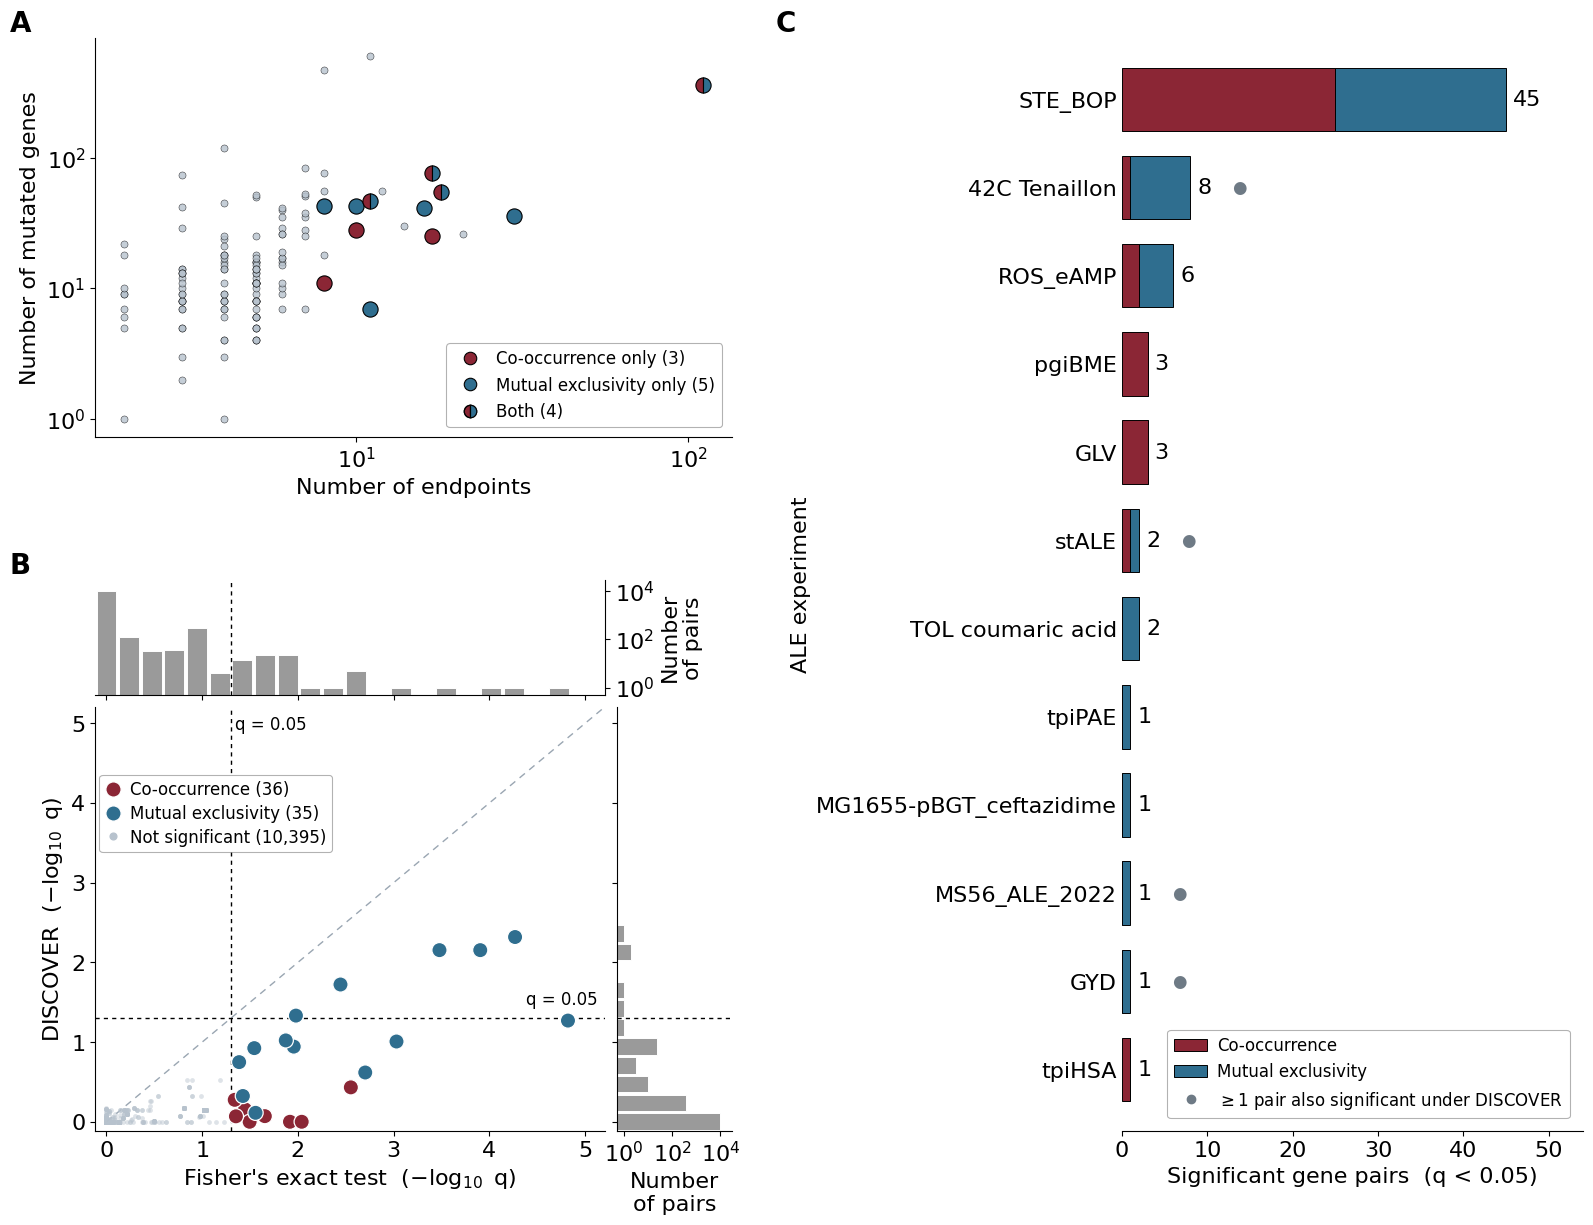

In [6]:
# %% Combined figure: the three panels drawn on ONE canvas.
# Drawn together rather than stitched: every text element is set in the same absolute point
# size (the FS dict) and nothing is rescaled afterwards, so the typography is consistent by
# construction.
#
#   +---------------+-----------------+   A and B are scatters and stack on the left.
#   |  A  scale     |                 |   C is a bar chart with one row per experiment
#   +---------------+  C  where the   |   and needs the height, so it takes the full
#   |  B  q vs q    |     calls are   |   right column.
#   +---------------+-----------------+
#
# Panel letters A to C are drawn at the end of this cell, above the panels.

# 12.5 in tall, with a slightly wider left column: panel B carries count bars along both axes,
# and its scatter needs room of its own besides them. The width is 16 in, so 16 pt text
# prints at 6.7 pt at 170 mm.
FIG_W, FIG_H = 16, 12.5
OUTER_L = 1.1                       # the left column's share of the width, out of 2
B_HEIGHT_RATIO = 1.38               # B's slot height relative to A's
B_MARG_IN, B_MARG_GAP = 1.15, 0.12  # B's count-bar thickness and its gap to the scatter, inches
C_SHIFT_IN = 0.60                   # inches C's left edge moves right, to make room for its y title
                                    # and space between the two columns (C keeps its right edge)

# A and B are the two scatters and stack on the left. C is a bar chart with one row per
# experiment and takes the full height on the right. Every panel is drawn with the SAME FS
# entries, so the typography is identical across the three.
fig = plt.figure(figsize=(FIG_W, FIG_H))
outer = fig.add_gridspec(1, 2, width_ratios=[OUTER_L, 2 - OUTER_L], wspace=0.57,
                         left=0.055, right=0.985, top=0.960, bottom=0.085)
lcol = outer[0].subgridspec(2, 1, height_ratios=[1.0, B_HEIGHT_RATIO], hspace=0.30)
axA = fig.add_subplot(lcol[0])
axC = fig.add_subplot(outer[1])
_pc = axC.get_position()
axC.set_position([_pc.x0 + C_SHIFT_IN / FIG_W, _pc.y0, _pc.width - C_SHIFT_IN / FIG_W, _pc.height])
# B is the scatter plus its two count bars. They are cut from B's slot by hand, not by a
# gridspec, so that both bars get the same thickness in inches (B_MARG_IN): they share one
# log count scale, and a count must draw the same length in both.
_sb = lcol[1].get_position(fig)
_mx, _my = B_MARG_IN / FIG_W, B_MARG_IN / FIG_H
_gx, _gy = B_MARG_GAP / FIG_W, B_MARG_GAP / FIG_H
axB  = fig.add_axes([_sb.x0, _sb.y0, _sb.width - _mx - _gx, _sb.height - _my - _gy])
axBT = fig.add_axes([_sb.x0, _sb.y1 - _my, _sb.width - _mx - _gx, _my], sharex=axB)
axBR = fig.add_axes([_sb.x1 - _mx, _sb.y0, _mx, _sb.height - _my - _gy], sharey=axB)


# ----------------------------------------------------------------- A. experiments
_base = per_exp[(per_exp["endpoints"] >= N_ENDPOINT_MIN) & per_exp["none"]]
_co   = per_exp[per_exp["co_only"]]
_me   = per_exp[per_exp["me_only"]]
_bo   = per_exp[per_exp["both_dir"]]

axA.scatter(_base["endpoints"], _base["genes"], s=26, color=C_BG,
            edgecolor=INK, linewidth=0.35, alpha=0.8, zorder=4)
axA.scatter(_co["endpoints"], _co["genes"], s=120, facecolor=C_CO,
            edgecolor=INK, linewidth=0.8, zorder=6)
axA.scatter(_me["endpoints"], _me["genes"], s=120, facecolor=C_ME,
            edgecolor=INK, linewidth=0.8, zorder=6)
axA.scatter(_bo["endpoints"], _bo["genes"], s=120, facecolor=C_CO, edgecolor=INK, linewidth=0.8,
            marker=MarkerStyle("o", fillstyle="left"), zorder=7)
axA.scatter(_bo["endpoints"], _bo["genes"], s=120, facecolor=C_ME, edgecolor=INK, linewidth=0.8,
            marker=MarkerStyle("o", fillstyle="right"), zorder=7)

# No cut-off line: every experiment with >= 2 endpoints is screened, and which pairs are
# testable is decided per pair from the margins, not by an experiment-level threshold.

axA.set_xscale("log"); axA.set_yscale("log")
axA.set_xlabel("Number of endpoints", fontsize=FS["axis_title"], color=INK)
axA.set_ylabel("Number of mutated genes", fontsize=FS["axis_title"], color=INK)
axA.tick_params(colors=INK, labelsize=FS["tick"])
axA.minorticks_off()
axA.set_axisbelow(True)

_dot = lambda c, fs="full": Line2D([], [], ls="", marker=MarkerStyle("o", fillstyle=fs),
                                   mfc=c, mec=INK, mew=0.8, ms=9)
_legA = axA.legend(
    [_dot(C_CO), _dot(C_ME), (_dot(C_CO, "left"), _dot(C_ME, "right"))],
    [f"Co-occurrence only ({len(_co)})",
     f"Mutual exclusivity only ({len(_me)})",
     f"Both ({len(_bo)})"],
    handler_map={tuple: HandlerTuple(ndivide=1, pad=0)},
    loc="lower right", frameon=True, fontsize=FS["legend"],
    handletextpad=0.6, borderaxespad=0.6)
_fr = _legA.get_frame()
_fr.set_alpha(None); _fr.set_facecolor("white")
_fr.set_edgecolor((0.0, 0.0, 0.0, 0.30)); _fr.set_linewidth(0.8)


# ------------------------------------------------------------------- B. q-q scatter
# Every marker the same size (s=120, as panel A's highlighted experiments), no size key, and
# gray count bars for every comparison along both axes (draw_marginals). The count axes
# use the figure's own tick and title sizes, so their exponents (10^0, 10^2, 10^4) stay
# legible in print. At 16 pt the top bar's scale and two-line title do not fit on its left,
# so they sit on its right, in the empty corner above the right-hand bar, and B's own y title
# stays next to its ticks.
# The knobs worth tuning when the panel is resized:
#   B_LEGEND_*     where the color legend sits (pad is the gap to the axes, in font units).
#                  No size key is drawn, so the empty triangle above the diagonal is free for
#                  it: at the bottom right it would cover points, because the count bars take
#                  their share of the width.
#   B_EQUAL_TEXT   label on the 1:1 diagonal, "" leaves it off
#   B_Q_*_OFFSET   offsets in POINTS for the two "q = 0.05" labels, (dx, dy)
B_LEGEND_LOC, B_LEGEND_PAD, B_LEGEND_ANCHOR = "upper left", 0.25, (0.0, 0.85)
B_EQUAL_TEXT, B_EQUAL_POS, B_EQUAL_ROT = "", (0.965, 0.985), 45
B_Q_VERT_OFFSET  = (3, -3)      # label on the vertical threshold line
B_Q_HORIZ_OFFSET = (0, 7)       # label on the horizontal threshold line

draw_qq(axB, FS["axis_title"], FS["tick"], FS["legend"], ms=120, ms_null=12,
        legend_loc=B_LEGEND_LOC, legend_pad=B_LEGEND_PAD, legend_anchor=B_LEGEND_ANCHOR,
        equal_text=B_EQUAL_TEXT, equal_pos=B_EQUAL_POS, equal_rot=B_EQUAL_ROT,
        q_vert_offset=B_Q_VERT_OFFSET, q_horiz_offset=B_Q_HORIZ_OFFSET,
        size_per_pair=0, size_legend_loc=None)
draw_marginals(axB, axBT, axBR, FS["tick"], FS["axis_title"], top_scale="right")


# --------------------------------------------------------------- C. where they come from
draw_concentration(axC, FS["axis_title"], FS["tick"], FS["legend"])
axC.set_ylabel("ALE experiment", fontsize=FS["axis_title"], color=INK)


# ----------------------------------------------------------------------- panel letters
# Each letter sits PANEL_LETTER_PAD above the top of its panel's ink, so A and C share a
# baseline. C sits PANEL_LETTER_LEFT left of its column's ink (axis title included). The left
# column's ink starts close to the canvas's left edge, so A and B sit PANEL_LETTER_EDGE from that
# edge instead. The canvas is not cropped on saving, so the run stops if a letter falls outside it.
PANEL_LETTER_PAD = 0.06      # inches between the top of a panel's ink and its letter's baseline
PANEL_LETTER_LEFT = 0.15     # inches between C and the left edge of its column's ink
PANEL_LETTER_EDGE = 0.03     # inches between A and B and the left edge of the canvas
fig.canvas.draw()
_r = fig.canvas.get_renderer()
_ink = lambda axes: [a.get_tightbbox(_r) for a in axes]
_x_ab = PANEL_LETTER_EDGE / FIG_W
_x_c = min(b.x0 for b in _ink((axC,))) / fig.bbox.width - PANEL_LETTER_LEFT / FIG_W
_y_ac = max(b.y1 for b in _ink((axA, axC))) / fig.bbox.height + PANEL_LETTER_PAD / FIG_H
_y_b = max(b.y1 for b in _ink((axB, axBT, axBR))) / fig.bbox.height + PANEL_LETTER_PAD / FIG_H
_letters = [fig.text(_x, _y, _l, ha="left", va="baseline", fontsize=FS["panel_label"],
                     fontweight="bold", color=INK)
            for _l, _x, _y in [("A", _x_ab, _y_ac), ("B", _x_ab, _y_b), ("C", _x_c, _y_ac)]]
fig.canvas.draw()
for _t in _letters:
    _e = _t.get_window_extent(_r)
    if _e.x0 < 0 or _e.y1 > fig.bbox.height:
        raise RuntimeError(f"panel letter {_t.get_text()} falls outside the canvas")


# ------------------------------------------------------------------------- save
# bbox_inches is NOT "tight": the margins above are deliberate, and cropping them would undo
# the clearance that keeps C's row labels off panels A and B.
if SAVE:
    _out = FIG_DIR / "Figure_3.svg"
    fig.savefig(_out, facecolor="white")
    fig.savefig(FIG_DIR / "Figure_3.png", dpi=DPI, facecolor="white")
    # SVG text is set to Arial, so it opens in Arial in Illustrator
    _t = _out.read_text()
    _t = re.sub(r'(font:\s*(?:[a-z]+\s+|\d+\s+)*[\d.]+px\s+)[^;"]*',
                r'\1Arial, Helvetica, sans-serif', _t)
    _out.write_text(_t)
    print(f"wrote {_out.relative_to(ROOT)}  ({FIG_W} x {FIG_H} in)")

plt.show()